# Inferencia del modelo — House Pricing

Este notebook genera las predicciones de `SalePrice` para los datos crudos de `test.csv` con el modelo ganador y construye el pipeline de inferencia, que integra todo el flujo en un solo objeto: selección de columnas, preprocesamiento, modelo y conversión a dólares.

## 1. Librerías

Importación de las librerías para manipulación de datos, carga de modelos y construcción del pipeline de inferencia.

In [1]:
import os

os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"  # Evita un aviso informativo de MLflow al importarlo

from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from mlflow import MlflowClient
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.frozen import FrozenEstimator
from sklearn.pipeline import Pipeline

## 2. Configuración y carga de datos

Lectura de `pipeline_config.yaml` y de los datos crudos de `test.csv`, sin ninguna transformación previa.

In [2]:
PROJ_ROOT = Path("..")
CONFIG_PATH = PROJ_ROOT / "pipeline_config.yaml"

with open(CONFIG_PATH, encoding="utf-8") as f:
    config = yaml.safe_load(f)

TARGET = config["TARGET"]
ID_COLUMN = "Id"
MODEL_FEATURES = config["MODEL_FEATURES"]
RAW_DIR = PROJ_ROOT / config["DATA"]["RAW_DIR"]

raw_test = pd.read_csv(RAW_DIR / config["DATA"]["TEST_FILE"])

print(f"raw_test: {raw_test.shape}")

raw_test: (1459, 80)


## 3. Carga del modelo champion desde MLflow

Se carga del Model Registry la versión con el alias `champion-<algoritmo>`. El modelo contiene el preprocesamiento y el algoritmo, ajustados con el 80% de los datos de entrenamiento, por lo que ningún paso se ajusta con los datos de `test`. Si el alias se mueve a otra versión en MLflow, este notebook usa automáticamente el nuevo champion.

In [3]:
REGISTERED_MODEL = config["MLFLOW"]["REGISTERED_MODEL"]

mlflow.set_tracking_uri(
    f"sqlite:///{(PROJ_ROOT / config['MLFLOW']['TRACKING_DB']).resolve().as_posix()}"
)
client = MlflowClient()

champion_alias, champion_version = next(
    (alias, version)
    for alias, version in client.get_registered_model(REGISTERED_MODEL).aliases.items()
    if alias.startswith("champion-")
)
champion_algorithm = client.get_run(
    client.get_model_version(REGISTERED_MODEL, champion_version).run_id
).data.tags["algorithm"]

winner_model = mlflow.sklearn.load_model(f"models:/{REGISTERED_MODEL}@{champion_alias}")

print(f"Champion: {champion_alias} (versión {champion_version}, {champion_algorithm})")
list(winner_model.named_steps)

Champion: champion-gradientboosting (versión 1, GradientBoosting)


['preprocessing', 'model']

## 4. Generación de predicciones

Se seleccionan las variables del modelo y se aplica el pipeline. El modelo devuelve el precio en escala logarítmica, por lo que las predicciones se regresan a dólares con `np.expm1`.

In [4]:
predictions = pd.DataFrame(
    {
        ID_COLUMN: raw_test[ID_COLUMN],
        TARGET: np.expm1(winner_model.predict(raw_test[MODEL_FEATURES])),
    }
)

print(f"Predicciones: {len(predictions)} | Valores vacíos: {predictions[TARGET].isna().sum()}")
predictions[TARGET].describe().round(0)

Predicciones: 1459 | Valores vacíos: 0


count      1459.0
mean     177542.0
std       75294.0
min       45703.0
25%      128054.0
50%      156401.0
75%      207684.0
max      525435.0
Name: SalePrice, dtype: float64

## 5. Pipeline de inferencia

Integración del flujo completo en un `Pipeline` de scikit-learn:

- **`ColumnTransformer`:** conserva y ordena las 30 variables del modelo, descarta las demás y genera un error si falta alguna.
- **`TransformedTargetRegressor`:** convierte la salida a dólares con `np.expm1`.
- **`FrozenEstimator`:** impide reentrenar el modelo ganador, de modo que `fit` no altera el preprocesamiento ni el modelo.

`fit` no aprende nada de los datos: solo registra la estructura de columnas de `train.csv`.

In [5]:
raw_train = pd.read_csv(RAW_DIR / config["DATA"]["TRAIN_FILE"])

column_selector = ColumnTransformer(
    [("features", "passthrough", MODEL_FEATURES)],
    verbose_feature_names_out=False,
).set_output(transform="pandas")

inference_pipeline = Pipeline([
    ("column_selector", column_selector),
    (
        "model",
        TransformedTargetRegressor(
            regressor=FrozenEstimator(winner_model),
            func=np.log1p,
            inverse_func=np.expm1,
        ),
    ),
])

inference_pipeline.fit(raw_train, raw_train[TARGET])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('column_selector', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](81,)","['Id','MSSubClass','MSZoning',...,'SaleType','SaleCondition','SalePrice']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,81
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('features', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and 

### 5.1 Comprobación del pipeline de inferencia

El pipeline recibe directamente las 80 columnas crudas de `test.csv`. Sus predicciones deben coincidir con las de la sección 4.

In [6]:
pipeline_predictions = inference_pipeline.predict(raw_test)

assert np.allclose(pipeline_predictions, predictions[TARGET])
print("Las predicciones del pipeline coinciden con las de la sección 4.")

Las predicciones del pipeline coinciden con las de la sección 4.


## 6. Guardado de resultados

Se guardan las predicciones en `data/processed/`, con el formato `Id` y `SalePrice` en dólares, y el pipeline de inferencia en `models/`. Sus rutas se agregan a `pipeline_config.yaml`.

In [7]:
PREDICTIONS_PATH = "data/processed/predictions.csv"
INFERENCE_PIPELINE_PATH = "models/inference_pipeline.joblib"

predictions.to_csv(PROJ_ROOT / PREDICTIONS_PATH, index=False)
joblib.dump(inference_pipeline, PROJ_ROOT / INFERENCE_PIPELINE_PATH)

config["INFERENCE"] = {
    "PIPELINE_PATH": INFERENCE_PIPELINE_PATH,
    "PREDICTIONS_PATH": PREDICTIONS_PATH,
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False, allow_unicode=True)

predictions.head()

,Id,SalePrice
0,1461,123532.491984
1,1462,153769.906705
2,1463,183211.015233
3,1464,191462.910069
4,1465,200673.287167


## 7. Inferencia desde la terminal

El mismo flujo está disponible en `house_pricing/modeling/predict.py`. Desde la raíz del proyecto, con el entorno `env_house_pricing` activo:

```bash
python -m house_pricing.modeling.predict
```

Por defecto lee `data/raw/test.csv` y escribe `data/processed/predictions.csv`. Las opciones `--input` y `--output` permiten cambiar ambas rutas. El archivo de entrada debe incluir la columna `Id`.

## 8. Comparación de distribuciones de `SalePrice`

Gráfica de densidad de los precios reales de `train.csv` frente a los precios producidos por el pipeline de inferencia para `test.csv`, ambos en dólares. Una forma similar indica que las predicciones conservan la distribución de los datos de entrenamiento. Esta comparación no mide la exactitud del modelo, ya que `test.csv` no incluye precios reales.

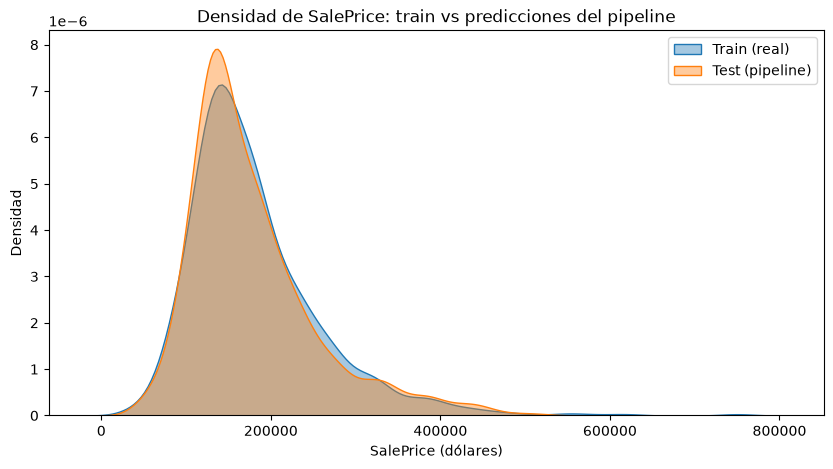

In [8]:
density_fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(x=raw_train[TARGET], fill=True, alpha=0.4, label="Train (real)", ax=ax)
sns.kdeplot(x=pipeline_predictions, fill=True, alpha=0.4, label="Test (pipeline)", ax=ax)
ax.set_title(f"Densidad de {TARGET}: train vs predicciones del pipeline")
ax.set_xlabel(f"{TARGET} (dólares)")
ax.set_ylabel("Densidad")
ax.legend()
plt.show()

## 9. Registro de la inferencia en MLflow

Se registra un run en el experimento de inferencia con:

- **Tags:** versión, alias y algoritmo del champion utilizado.
- **Parámetros:** archivo de entrada y número de filas.
- **Métricas:** estadísticas de las predicciones en dólares.
- **Artefactos:** `predictions.csv` y la gráfica de densidad de la sección 8.

In [9]:
INFERENCE_EXPERIMENT = config["MLFLOW"]["INFERENCE_EXPERIMENT"]

if mlflow.get_experiment_by_name(INFERENCE_EXPERIMENT) is None:
    mlflow.create_experiment(
        INFERENCE_EXPERIMENT,
        artifact_location=(PROJ_ROOT / config["MLFLOW"]["ARTIFACTS_DIR"]).resolve().as_uri(),
    )
mlflow.set_experiment(INFERENCE_EXPERIMENT)

prediction_stats = predictions[TARGET].describe()

with mlflow.start_run(run_name=f"inferencia-{champion_alias}"):
    mlflow.set_tags(
        {
            "registered_model": REGISTERED_MODEL,
            "model_alias": champion_alias,
            "model_version": champion_version,
            "algorithm": champion_algorithm,
        }
    )
    mlflow.log_params({"archivo_entrada": config["DATA"]["TEST_FILE"], "filas": len(raw_test)})
    mlflow.log_metrics(
        {
            "prediccion_media": prediction_stats["mean"],
            "prediccion_mediana": prediction_stats["50%"],
            "prediccion_desviacion": prediction_stats["std"],
            "prediccion_minima": prediction_stats["min"],
            "prediccion_maxima": prediction_stats["max"],
        }
    )
    mlflow.log_artifact(str(PROJ_ROOT / PREDICTIONS_PATH), artifact_path="predicciones")
    mlflow.log_figure(density_fig, "graficas/densidad_saleprice.png")

print(f"Inferencia registrada con {champion_alias} (versión {champion_version}).")

Inferencia registrada con champion-gradientboosting (versión 1).
